In [1]:
from keras.layers import Lambda, Input, Dense
from keras.models import Model
from keras.losses import mse, binary_crossentropy
from keras import backend as K
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import random
import tensorflow as tf

cmap='tab10'

## Supplementary Materials — English 3D-VAE final model

**Execution workflow (documentation revised in 2026; this notebook has not been re-executed).** The analysis was performed in two stages, not by running every cell in sequence in one session.

### Stage 1 — Model training and weight export

1. Prepare the data, inspect the seed-search results in `VAEloss_English_20240411ver0.1.csv`, and train the VAE with **seed 26172** (30 epochs).
2. Execute the active weight-extraction cell to obtain the fitted encoder and decoder weights and biases.
3. Run the **Export trained weights** cell to save the five weight CSV files under `VAEeng3D20240411_weight/`. **Skip this export cell when using previously saved weights**: running it again can overwrite those CSV files.
4. The saved-weight loading and grid-based decoder computation are not part of this stage.

### Stage 2 — Decoder computation from previously saved weights

1. In a fresh runtime, run the imports and mount Google Drive. **Do not run the VAE training cell.** The encoder-dependent latent-space visualizations must also be skipped.
2. Run the independent **Create latent-space grid** cell to define the 30 × 30 × 30 points (27,000 points in total).
3. **Remove the triple quotes** around the **Load saved decoder weights** cell and execute it. The cell is disabled by default in this SM edition.
4. Run the subsequent NumPy decoder-calculation and DataFrame cells to obtain the 680-dimensional outputs. To write the results, uncomment and run the `VAEdecAlleng3D20240411.csv` export statement. This may overwrite an existing result CSV.

**Historical note.** The five weight-export statements were executed during the original training stage, and were subsequently enclosed in triple quotes to prevent repeated export. They have been restored to executable form for the present documented Stage 1. Conversely, the decoder-weight loading code was executed during Stage 2 and is now enclosed in triple quotes to make its conditional use explicit. The decoder-output CSV export statement was also run previously and later commented out. The saved results remain historical outputs, not outputs generated by running this curated notebook. The 2026 editing also removed obsolete or unused code, translated explanatory comments, and renamed the seed-search CSV; the original notebook remains separately preserved.

### Data preprocessing


In [2]:
# Define this function for reproducibility before calling fit
# Setting the seed alone did not reproduce the same results, so this additional setup was adopted from an online source

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    session_conf = tf.compat.v1.ConfigProto(
        intra_op_parallelism_threads=1,
        inter_op_parallelism_threads=1
    )
    sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
    tf.compat.v1.keras.backend.set_session(sess)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!ls /content/drive/MyDrive/dataset

english-all.csv				MandarinBeijing_WS_20230907_shaped_format.csv
english_american.csv			mandarin.csv
EnglishAmerican_WS_20240411_shaped.csv	VAEloss中国語new.csv
english.csv				VAEloss英語_20240411bkup.csv
JMCDI_SPSE_1_ageM.csv			VAEloss英語_20240411ver0.0.csv
JMCDI_SPSE_2_ageM.csv			VAEloss英語_20240411ver0.1.csv
mandarin_beijing.csv			VAEloss英語5.csv
MandarinBeijing_WS_20230907_shaped.csv


In [ ]:
"""

# Support for wide-format data
df = pd.read_csv('/content/drive/MyDrive/dataset/EnglishAmerican_WS_20230907_reconstructed_wide.csv', index_col=1)# English
df=df.fillna(0)# Replace missing values with 0
age=df.age.values
df=df.replace(['produces'], 1)# Convert responses to binary (0/1) data
df=df.drop(['downloaded',"child_id","age"],axis=1)
dim=len(df.values[0])

"""

<ipython-input-3-b22934011394>:2: DtypeWarning: Columns (175,181,187,262,269,280,283,313,318,329,331,333,346,375,411,419,421,428,434,439,441,452,454,460,463,469,475,481,485,490,493,494,504,539,544,552,563,570,571,577,578,579,581,582,583,592,593,594,596,597,598,599,601,602,606,609,611,615,620,621,627,628,629,632,634,636,637,639,643,645,646,647,649,653,658,659,661,664,666,667,668,672,674,675,676,677,678,680,681,682,683) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/dataset/EnglishAmerican_WS_20230907_reconstructed_wide.csv', index_col=1)#英語


In [ ]:
## Code to format data downloaded from Wordbank ##
## Commented out because this is not currently needed ##



#df = pd.read_csv('/content/drive/MyDrive/dataset/mandarin_beijing.csv', index_col=0)# Mandarin Chinese
df = pd.read_csv('/content/drive/MyDrive/dataset/EnglishAmerican_WS_20240411_shaped.csv', index_col=1)# English
df=df.fillna(0)# Replace missing values with 0
df=df[df['item_kind'] =='word']# Keep only word items
df=df.replace('produces', 1)# Convert responses to binary (0/1)
index=list(dict.fromkeys(df.index))# Obtain index values
index=[int(item) for item in index]
n=len(index)# Number of children
dim=len(df.loc[index[0]])# Number of items
age=df.age.values.reshape(n,dim).T[0]

# Create headers and an index
import string
import collections
cate=list(dict.fromkeys(df.category[index[0]]))# List of categories
name=[chr(i) for i in range(65, 65+len(cate))]# Generate labels A, B, C, etc.

header=[]
for na,i in enumerate(cate):
  for j in range(collections.Counter(df.category[index[0]])[i]):
    header.append(name[na]+str(j+1))


In [6]:
df=pd.DataFrame(data=df.value.values.reshape(n,dim),index=index,columns=header)

In [7]:
df

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,...,U18,U19,U20,U21,V1,V2,V3,V4,V5,V6
396587,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,0,0,1,1,1
396588,1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,1,0,1,0,0,0
396589,1,1,1,1,1,1,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
396590,1,1,0,1,0,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
396591,1,1,0,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
406721,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
406724,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
406727,1,1,1,1,1,1,0,1,1,0,...,1,0,1,0,1,1,1,0,1,1
406729,0,1,0,1,0,1,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
## Load loss data from 1,000 trials
#loss_data=pd.read_csv('/content/drive/MyDrive/dataset/VAEloss英語reconst_3d.csv',index_col=0)

In [8]:
# Load loss data from 1,000 trials
loss_data=pd.read_csv('/content/drive/MyDrive/dataset/VAEloss_English_20240411ver0.1.csv',index_col=0)

In [9]:
loss_asce=loss_data.sort_values('loss')
val_loss_asce=loss_data.sort_values('val_loss')

In [10]:
# Display results in ascending order of val_loss
val_loss_asce[:20]

,loss,val_loss
seed,,
26172,197.577377,186.898148
58423,196.901016,188.918060
90209,196.695953,189.160156
11972,196.709015,189.239075
37744,196.558090,189.432877
27079,196.802994,189.495422
74457,196.630753,189.785095
66513,196.789993,189.852554
56747,196.334259,190.001846


In [ ]:
val_loss_asce.index[:10]

Index([26172, 58423, 90209, 11972, 37744, 27079, 74457, 66513, 56747, 55478], dtype='int64', name='seed')

In [ ]:
# Examine the seeds with favorable val_loss in more detail below

### Stage 1 — Train the VAE with seed 26172

Run the training cell below **only for Stage 1**. In Stage 2, use the saved decoder weights instead and skip this cell (and any subsequent code that relies on a live `encoder` or `vae`).

In [11]:
seed_everything(26172)
# Split the test set without stratifying by age in months
# Following the MNIST example, divide the data into seven parts
test=df.sample(frac=1/7)
tesindex=test.index
train=df.drop(test.index)


# network parameters
input_shape = (dim, )
intermediate_dim = 512
batch_size = 128
latent_dim = 3

# build encoder model
inputs = Input(shape=input_shape, name='encoder_input')
x = Dense(intermediate_dim, activation='relu')(inputs)
z_mean = Dense(latent_dim, name='z_mean')(x)
z_log_var = Dense(latent_dim, name='z_log_var')(x)


def sampling(args):
    z_mean, z_log_var = args
    batch = K.shape(z_mean)[0]
    dim = K.int_shape(z_mean)[1]
    epsilon = K.random_normal(shape=(batch, dim))
    return z_mean + K.exp(0.5 * z_log_var) * epsilon

# use reparameterization trick to push the sampling out as input
z = Lambda(sampling, output_shape=(latent_dim,), name='z')([z_mean, z_log_var])

# instantiate encoder model
encoder = Model(inputs, [z_mean, z_log_var, z], name='encoder')
#encoder.summary()

# build decoder model
latent_inputs = Input(shape=(latent_dim,), name='z_sampling')
x = Dense(intermediate_dim, activation='relu')(latent_inputs)
outputs = Dense(dim, activation='sigmoid')(x)

# instantiate decoder model
decoder = Model(latent_inputs, outputs, name='decoder')
#decoder.summary()


# instantiate VAE model
outputs = decoder(encoder(inputs)[2])
vae = Model(inputs, outputs)


# VAE loss = mse_loss or xent_loss + kl_loss
reconstruction_loss = binary_crossentropy(inputs,outputs)*dim

kl_loss = 1 + z_log_var - K.square(z_mean) - K.exp(z_log_var)
kl_loss = -0.5*K.sum(kl_loss, axis=-1)

vae_loss = K.mean(reconstruction_loss + kl_loss)
vae.add_loss(vae_loss)
vae.compile(optimizer='adam')
#vae.summary()

result=vae.fit(train,
          epochs=30,
          batch_size=batch_size,
          validation_data=(test, None))

Epoch 1/30
61/61 [==============================] - 4s 8ms/step - loss: 305.0361 - val_loss: 210.3890
Epoch 2/30
61/61 [==============================] - 0s 5ms/step - loss: 215.4443 - val_loss: 199.3498
Epoch 3/30
61/61 [==============================] - 0s 5ms/step - loss: 209.7024 - val_loss: 195.1975
Epoch 4/30
61/61 [==============================] - 0s 5ms/step - loss: 205.4913 - val_loss: 192.4302
Epoch 5/30
61/61 [==============================] - 0s 4ms/step - loss: 203.7642 - val_loss: 190.4433
Epoch 6/30
61/61 [==============================] - 0s 5ms/step - loss: 203.2319 - val_loss: 190.5103
Epoch 7/30
61/61 [==============================] - 0s 5ms/step - loss: 202.0904 - val_loss: 191.2101
Epoch 8/30
61/61 [==============================] - 0s 5ms/step - loss: 201.6915 - val_loss: 189.1223
Epoch 9/30
61/61 [==============================] - 0s 4ms/step - loss: 201.4385 - val_loss: 189.2369
Epoch 10/30
61/61 [==============================] - 0s 5ms/step - loss: 201.0130 

In [12]:
vae.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 encoder_input (InputLayer)  [(None, 680)]                0         []                            
                                                                                                  
 encoder (Functional)        [(None, 3),                  351750    ['encoder_input[0][0]']       
                              (None, 3),                                                          
                              (None, 3)]                                                          
                                                                                                  
 decoder (Functional)        (None, 680)                  350888    ['encoder[0][2]']             
                                                                                              

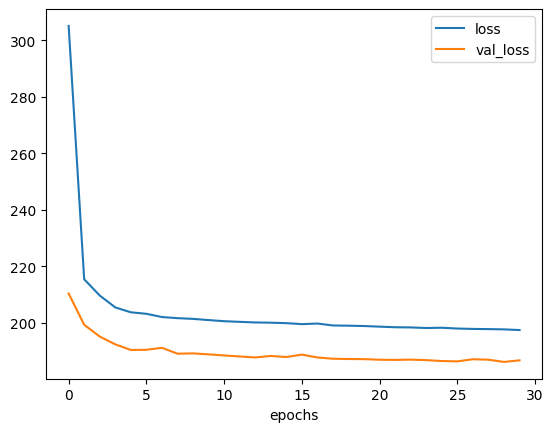

In [13]:
# Changes in loss and val_loss during training
plt.plot(result.history["loss"],label="loss")
plt.plot(result.history["val_loss"],label="val_loss")
plt.xlabel('epochs')

plt.legend()

In [14]:
we=encoder.get_layer('dense').get_weights()[0]
web=encoder.get_layer('dense').get_weights()[1]

wzm=encoder.get_layer('z_mean').get_weights()[0]
wzmb=encoder.get_layer('z_mean').get_weights()[1]
wzlv=encoder.get_layer('z_log_var').get_weights()[0]
wzlvb=encoder.get_layer('z_log_var').get_weights()[1]

wdd1=decoder.get_layer('dense_1').get_weights()[0]
wdd1b=decoder.get_layer('dense_1').get_weights()[1]

wdd2=decoder.get_layer('dense_2').get_weights()[0]
wdd2b=decoder.get_layer('dense_2').get_weights()[1]

In [ ]:
## Code to extract weight matrices W
## Restart the runtime, train only the model with the target seed, and then run this code ##

"""
we=encoder.get_layer('dense').get_weights()[0]
web=encoder.get_layer('dense').get_weights()[1]

wzm=encoder.get_layer('z_mean').get_weights()[0]
wzmb=encoder.get_layer('z_mean').get_weights()[1]
wzlv=encoder.get_layer('z_log_var').get_weights()[0]
wzlvb=encoder.get_layer('z_log_var').get_weights()[1]

wdd1=decoder.get_layer('dense_1').get_weights()[0]
wdd1b=decoder.get_layer('dense_1').get_weights()[1]

wdd2=decoder.get_layer('dense_2').get_weights()[0]
wdd2b=decoder.get_layer('dense_2').get_weights()[1]

"""

### Stage 1 — Export trained weights (five CSV files)

After training, run the active weight-extraction cell above, followed by the export cell below. **Do not run this export cell if you do not intend to write weight files**: the same paths will be used and existing files may be overwritten. The original analysis executed these exports before subsequently disabling them.

In [ ]:
wname=["weD"+str(i) for i in range(len(we)+1)]
pd.DataFrame(np.concatenate([[web],we]).T,columns=wname).to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEweD_eng3D20240411.csv',index=None)

wname=["weZm"+str(i) for i in range(len(wzm)+1)]
pd.DataFrame(np.concatenate([[wzmb],wzm]).T,columns=wname).to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEweZm_eng3D20240411.csv',index=None)
wname=["weZlv"+str(i) for i in range(len(wzlv)+1)]
pd.DataFrame(np.concatenate([[wzlvb],wzlv]).T,columns=wname).to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEweZlv_eng3D20240411.csv',index=None)

wname=["wdD1_"+str(i) for i in range(len(wdd1)+1)]
pd.DataFrame(np.concatenate([[wdd1b],wdd1]).T,columns=wname).to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD1_eng3D20240411.csv',index=None)

wname=["wdD2_"+str(i) for i in range(len(wdd2)+1)]
pd.DataFrame(np.concatenate([[wdd2b],wdd2]).T,columns=wname).to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD2_eng3D20240411.csv',index=None)


285/285 [==============================] - 0s 1ms/step


Text(0.5, 0, 'z3')

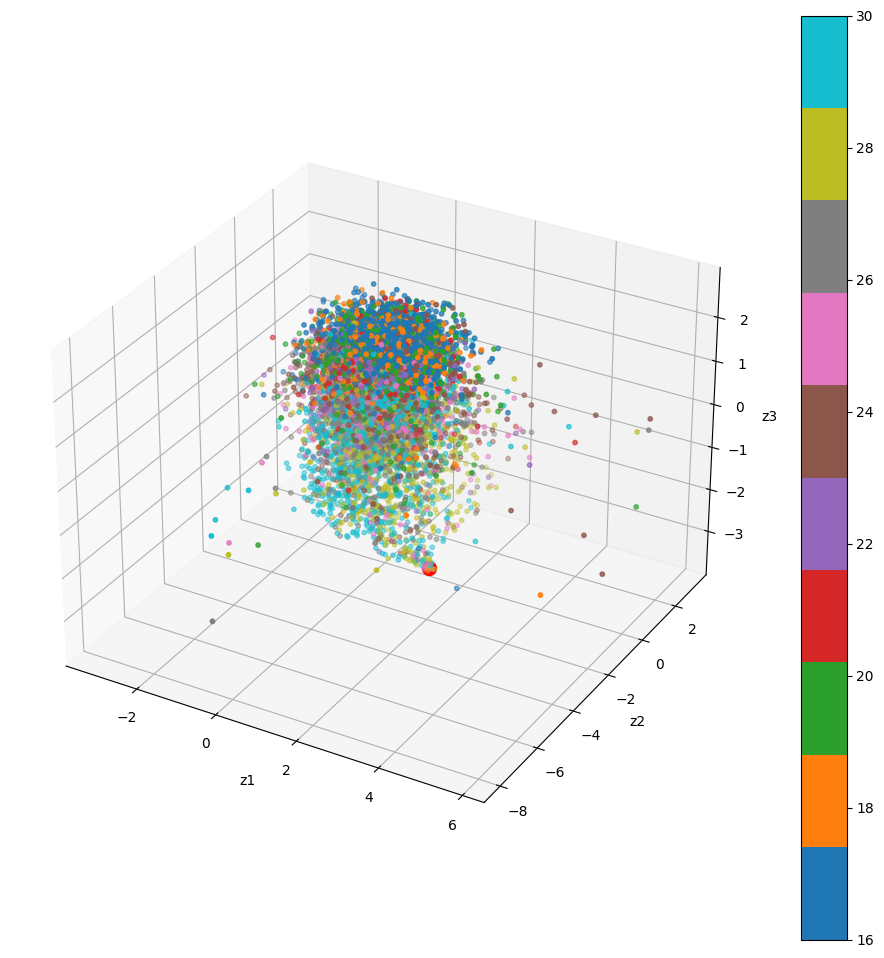

In [25]:
# Plot the latent space
# Coloring by age in months did not work as expected despite several attempts (this may be acceptable if plotting is done in Mathematica)

zeroco =encoder.predict(np.array([np.zeros(dim)]))[0][0]
oneco =encoder.predict(np.array([np.ones(dim)]))[0][0]

z_mean, _, _ = encoder.predict(df)

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')


ax.scatter(zeroco[0],zeroco[1],zeroco[2],s=100,c="black")
ax.scatter(oneco[0],oneco[1],oneco[2],s=100,c="red")
tmp=ax.scatter(z_mean[:, 0], z_mean[:, 1],z_mean[:, 2],s=10, c=age, cmap=cmap)
fig.colorbar(tmp)
#plt.xlim(-6,6.2)
#plt.ylim(-6,6)

#plt.axes().set_aspect('equal')
ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")

### Stage 2 — Create latent-space grid (no training required)

Run the next cell to define the 30 × 30 × 30 latent grid. It does not depend on a trained Encoder. The following **latent-space plot** is optional and depends on `z_mean` from Stage 1; skip that plot when running Stage 2 from saved weights.

In [ ]:
# Create grid points; adjust the range as desired
n=30
grid_x = np.linspace(-4, 4, n)
grid_y = np.linspace(-4, 4, n)[::-1]
grid_z = np.linspace(-4, 4, n)[::-1]
grid=np.meshgrid(grid_x,grid_y,grid_z)


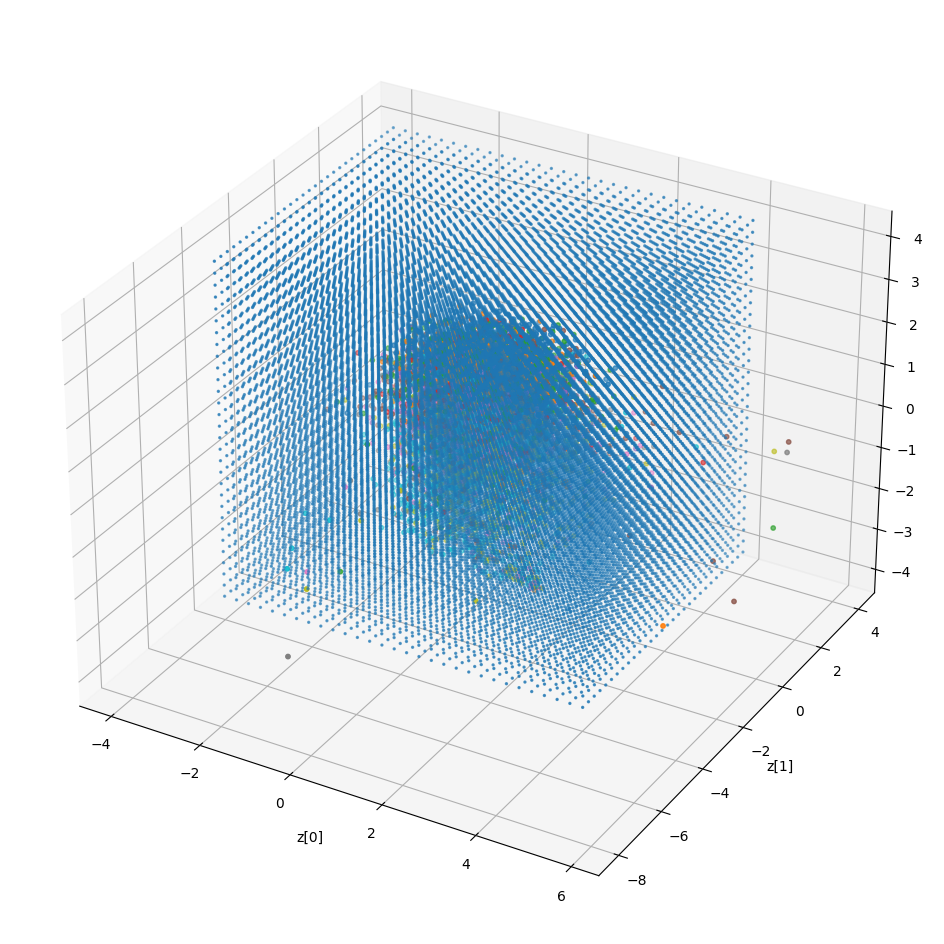

In [ ]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(grid[0],grid[1],grid[2],s=2)
ax.scatter(z_mean[:, 0], z_mean[:, 1],z_mean[:, 2],s=10, c=age, cmap=cmap)
plt.grid()
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.show()

### Stage 2 — Load saved decoder weights and biases

**Remove the opening and closing `"""` from the code cell immediately below, then run it.** This is necessary before computing `contourlist` with NumPy. The cell is disabled by default, reflecting the optional saved-weight workflow. **For Stage 1, leave it disabled.**

In [ ]:
"""
# Load decoder weights for the current model
wdd1=pd.read_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD1_eng3D20240411.csv',index_col=0).values# English
tmp=pd.read_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD1_eng3D20240411.csv')
wddb1=tmp.wdD1_0.values
wdd2=pd.read_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD2_eng3D20240411.csv',index_col=0).values# English
tmp=pd.read_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEwdD2_eng3D20240411.csv')
wddb2=tmp.wdD2_0.values
"""


In [31]:
griddata=[]
for i in range(30):
  for j in range(30):
    for k in range(30):
      griddata.append([grid_x[i],grid_y[j],grid_z[k]])
griddata=np.array(griddata)

In [32]:
tes=(griddata@wdd1.T+wddb1)
tes=np.where(tes <= 0, 0, tes)
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
contourlist=sigmoid(tes@wdd2.T+wddb2)

In [ ]:
# This code should probably produce the same results

"""
contourlist=[]
for i in range(30):
  for j in range(30):
    for k in range(30):
      contourlist.append(decoder.predict([[grid_x[i],grid_y[j],grid_x[k]]]))

"""

In [33]:
np.array(contourlist).shape

(27000, 680)

In [34]:
dfall=pd.DataFrame(contourlist.T)

In [35]:
dfall

,0,1,2,3,4,5,6,7,8,9,...,26990,26991,26992,26993,26994,26995,26996,26997,26998,26999
0,9.101229e-01,9.160085e-01,9.225676e-01,9.298194e-01,9.369012e-01,9.438967e-01,9.508624e-01,9.570820e-01,9.626794e-01,9.679706e-01,...,0.335012,0.411383,0.495336,0.581554,0.662767,0.738075,0.802554,0.855656,0.898799,0.931243
1,2.387979e-01,2.914305e-01,3.541531e-01,4.273794e-01,5.035815e-01,5.779013e-01,6.496185e-01,7.137273e-01,7.719372e-01,8.212497e-01,...,0.261443,0.337417,0.423169,0.516168,0.608778,0.694503,0.768300,0.828790,0.877075,0.914852
2,4.893855e-01,5.031847e-01,5.202086e-01,5.384945e-01,5.582094e-01,5.805326e-01,6.062923e-01,6.328935e-01,6.613173e-01,6.926028e-01,...,0.092068,0.136903,0.201775,0.290997,0.402405,0.527285,0.651141,0.758985,0.844990,0.906088
3,9.948046e-01,9.942990e-01,9.938368e-01,9.934370e-01,9.930566e-01,9.926705e-01,9.923640e-01,9.920903e-01,9.918647e-01,9.917185e-01,...,0.282682,0.360182,0.448101,0.540187,0.632719,0.718250,0.791364,0.850325,0.896571,0.931033
4,9.794499e-01,9.831465e-01,9.865946e-01,9.895715e-01,9.920049e-01,9.938758e-01,9.953753e-01,9.965215e-01,9.974048e-01,9.980696e-01,...,0.174741,0.240167,0.320902,0.414342,0.514080,0.614923,0.707598,0.788138,0.855330,0.906830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
675,4.565086e-11,1.452648e-10,4.574902e-10,1.412592e-09,4.154207e-09,1.174444e-08,3.258368e-08,8.706889e-08,2.265333e-07,5.739339e-07,...,0.986977,0.993279,0.996420,0.998029,0.998888,0.999358,0.999619,0.999766,0.999849,0.999901
676,1.795577e-11,4.460972e-11,1.087666e-10,2.605736e-10,5.983069e-10,1.304163e-09,2.777048e-09,5.748660e-09,1.165996e-08,2.320402e-08,...,0.970662,0.984485,0.991567,0.995280,0.997325,0.998442,0.999063,0.999417,0.999622,0.999745
677,2.978050e-12,7.259174e-12,1.729381e-11,4.025438e-11,8.907255e-11,1.881620e-10,3.878177e-10,7.692370e-10,1.489820e-09,2.800450e-09,...,0.987677,0.994132,0.997114,0.998540,0.999244,0.999597,0.999777,0.999871,0.999922,0.999951
678,4.951803e-09,1.048962e-08,2.175630e-08,4.395669e-08,8.581146e-08,1.627281e-07,3.034662e-07,5.422227e-07,9.503364e-07,1.627570e-06,...,0.950476,0.974810,0.986869,0.993003,0.996181,0.997851,0.998758,0.999256,0.999537,0.999702


### Stage 2 — Export the decoder grid outputs

The following CSV export line was run in the historical analysis and later commented out. **Uncomment it only when you intend to write the result** (`VAEdecAlleng3D20240411.csv`); running it can overwrite the previous file.

In [36]:
#dfall.to_csv('/content/drive/MyDrive/dataset/VAEeng3D20240411_weight/VAEdecAlleng3D20240411.csv',index=None,header=None)